In [1]:
# import os
# import sys
import torch
import torch.nn as nn
# import torch.nn.functional as F
import torchvision.transforms as transforms
# from pathlib import Path
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm

from utils.evaluate import evaluate
from unet import UNet

import numpy as np
import matplotlib.pyplot as plt

In [2]:
from fakeionogramdatasetOX import ParabolaIonoDatasetOX
from testionogramdataset import HandPickTraceDataset

In [3]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)


cuda:0


In [4]:
from torch.optim import AdamW

epochs = 10
batch_size = 5
learning_rate = 1e-4
val_percent = 0.1

weight_decay = 5e-3
momentum = 0.2
gradient_clipping = 1.0

target_size = [572,572] #[524,412]
original_size = [512,408]
resize = 'pad'

train_dataset = ParabolaIonoDatasetOX('training_data', target_size= target_size, resize=resize)

n_val = int(len(train_dataset) * val_percent)
n_train = len(train_dataset) - n_val
train_set, val_set = random_split(train_dataset, [n_train, n_val], generator=torch.Generator())

# 3. Create data loaders
loader_args = dict(batch_size=batch_size, num_workers=5, pin_memory=True) #os.cpu_count()

train_loader = DataLoader(train_set, shuffle=True, drop_last=True, **loader_args)

loader_args['batch_size'] = 1
val_loader = DataLoader(val_set, shuffle=True, drop_last=True, **loader_args)

test_dataset = HandPickTraceDataset('VIPIR_PROC/proc', 'VIPIR_PROC/dog_pick', target_size= target_size, resize=resize)
test_loader = DataLoader(test_dataset, shuffle=True, drop_last=True, **loader_args)


c:\Program Files\Python311\Lib\site-packages\torch\functional.py:512: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ..\aten\src\ATen\native\TensorShape.cpp:3588.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


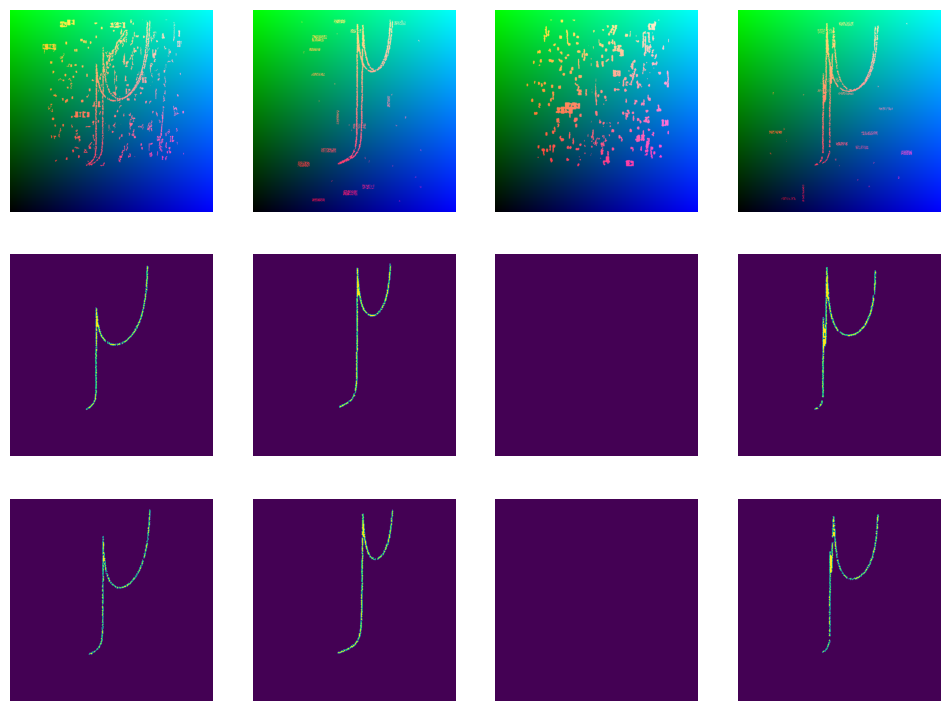

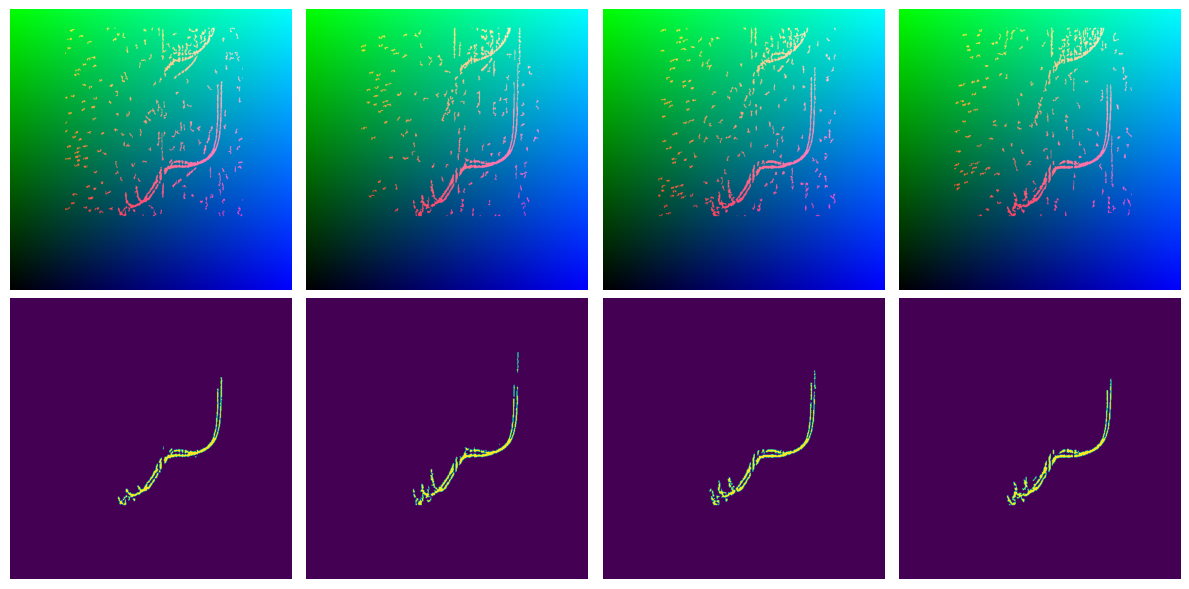

In [5]:
# visualize the training set

fig, axs = plt.subplots(ncols=4, nrows=3, figsize=(12, 9))
for idx, ax_i in enumerate(axs.T):
    target = train_dataset[idx]
    img = target["image"]
    gt = target["mask"]
    ax = ax_i[0]
    img = img.permute((1, 2, 0)).numpy()
    ax.imshow((img), origin = 'lower')
    ax.axis('off')
    ax = ax_i[1]
    gt = gt.numpy()
    ax.imshow((gt[0,:,:]).astype(np.uint8), origin = 'lower')
    ax.axis('off')
    ax = ax_i[2]
    ax.imshow((gt[1,:,:]).astype(np.uint8), origin = 'lower')
    ax.axis('off')
# fig.tight_layout()

# visualize the test set

fig, axs = plt.subplots(ncols=4, nrows=2, figsize=(12, 6))
for idx, ax_i in enumerate(axs.T):
    target = test_dataset[idx]
    img = target["image"]
    gt = target["mask"]
    ax = ax_i[0]
    img = img.permute((1, 2, 0)).numpy()
    ax.imshow((img), origin = 'lower')
    ax.axis('off')
    ax = ax_i[1]
    gt = gt.permute((1, 2, 0)).numpy()
    ax.imshow((gt).astype(np.uint8), origin = 'lower')
    ax.axis('off')
fig.tight_layout()

In [7]:
class DBCEF(nn.Module):
    """ DBCEF from paper https://arxiv.org/pdf/1906.05229 """

    def __init__(self, epsilon: float = 1e-4, gamma: float = 1.0):
        super().__init__()
        self.softmax = nn.Softmax(dim=1)
        self.epsilon = epsilon
        self.gamma = gamma

    def forward(self, input : torch.Tensor, target : torch.Tensor):
        y = torch.clamp(self.softmax(input), min = 1e-10, max = 1-1e-10)
        t = nn.functional.one_hot(target, num_classes = 2).permute(0, 3, 1, 2).contiguous()

        N = t.size()[-1]*t.size()[-2]
        beta = torch.sum(t,dim=(-1,-2))/N + self.epsilon 
        beta = beta[:,:,None,None]

        CE = t*torch.clamp(torch.log(y), min = -100)
        FCE = (1-y)**self.gamma*CE
        # FCE = CE
        DBCEF = FCE/beta

        return -1*torch.sum(DBCEF)/N/y.size()[0]
    

In [8]:
# Test on the TOPHAT test dataset
import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
testim = torch.from_numpy(testim['mask_full']).float()
XX, YY = torch.meshgrid(torch.linspace(0,1,testim.size()[0],dtype=torch.float32),torch.linspace(0,1,testim.size()[1],dtype=torch.float32))

@torch.no_grad()
def test_on_TOPHAT(model, epoch_num):    
    with torch.no_grad():
        for i in range(5):
            file = testfiles[np.random.randint(0,len(testfiles)-1)]
            testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

            testimage1 = torch.from_numpy(testdata['mask_full']).float()
            testimage1 = testimage1[None,None,:,:] #resize_tr(testimage1[None,None,:,:])
            img = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
            img = img.to('cuda')
            label1 = model(img)
            label1 = label1.squeeze().to('cpu')
            # transform = transforms.ToPILImage()
            # img = transform(label1)
            imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu().numpy()
            imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu().numpy()
            
            fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
            plt.title(f'epoch{epoch_num}_{file}')
            ax = axs[0]
            ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'auto')
            ax.axis('off')
            ax = axs[1]

            imgX[imgO==1]=2
            ax.imshow(imgX, origin='lower', aspect = 'auto')
            ax.axis('off')
            plt.savefig(f'testing_result/epoch{epoch_num}_{file[:-4]}.png', bbox_inches='tight')
            plt.close()
    return

In [ ]:
model = UNet(n_channels=3, n_classes=4, bilinear=False)
# model.load_state_dict(torch.load('path_to_save_model/'+'checkpoint_epoch_1.pth')['model_state_dict'])

# pretrained = torch.load('unet_carvana_scale1.0_epoch2.pth')
# model_pretrain = UNet(n_channels=3, n_classes=2, up_kernel_size=2, bilinear=False)
# model_pretrain.load_state_dict(pretrained)
# model = UNet(n_channels=3, n_classes=4, bilinear=False)
# model.down1 = model_pretrain.down1
# model.down2 = model_pretrain.down2
# model.down3 = model_pretrain.down3
# model.down4 = model_pretrain.down4

model = model.to(device=device)
model.train()

In [ ]:
optimizer = AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
dbcefloss = DBCEF()
dbcefloss = dbcefloss.to(device=device)
epcoh_elapsed = 0
losses = []
val_losses = []
test_losses = []

In [ ]:
epcoh_elapsed

In [ ]:
checkpoint_N = 400
for epoch in range(epcoh_elapsed,epcoh_elapsed+epochs):
    with tqdm(total=n_train, desc=f'Epoch {epoch+1}/{epochs}', unit='img') as pbar:
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            inputs, labels = data['image'], data['mask']
            inputs, labels = inputs.to(device), labels.to(device) 
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = dbcefloss(outputs[:,0:2,:,:], labels[:,0,:,:]) + dbcefloss(outputs[:,2:4,:,:], labels[:,1,:,:])
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            pbar.update(inputs.shape[0])
            pbar.set_postfix(**{'loss (batch)': loss.item()})
            del inputs; del labels
            if (i+1)%checkpoint_N == 0: # validation for every checkpoint_N batch
                losses += [running_loss / i]
                model.eval()
                with torch.no_grad():
                    val_loss = 0.0
                    for ii, data in enumerate(val_loader, 0):
                        inputs, labels = data['image'], data['mask']
                        inputs, labels = inputs.to(device), labels.to(device)
                        outputs = model(inputs)                
                        loss = dbcefloss(outputs[:,0:2,:,:], labels[:,0,:,:]) + dbcefloss(outputs[:,2:4,:,:], labels[:,1,:,:])
                        val_loss += loss.item()
                        del inputs; del labels
                    avg_val_loss = val_loss / len(val_loader)
                    val_losses += [avg_val_loss]
                    test_loss = evaluate(model,test_loader,device)
                    test_losses += [test_loss.cpu()]
                    print(f'Epoch: {epoch + 1}, Img:{(i+1)*batch_size} ,Validation Loss: {avg_val_loss:.4f}, Testing Dice_score: {test_loss:.4f}')
                    # pick 5 random ionogram for testing
                    test_on_TOPHAT(model, epoch+1)
                model.train()
                    
                fig, axs = plt.subplots(ncols=3, nrows=1, figsize=(12, 4))
                ax = axs[0]
                ax.plot(np.arange(len(losses))*checkpoint_N,losses)
                ax.set_xlabel('Steps');ax.set_ylabel('Training loss')
                ax = axs[1]
                ax.plot(np.arange(len(val_losses))*checkpoint_N,val_losses)
                ax.set_xlabel('Steps');ax.set_ylabel('Val loss')
                ax = axs[2]
                ax.plot(np.arange(len(test_losses))*checkpoint_N,test_losses)
                ax.set_xlabel('Steps');ax.set_ylabel('Val loss')
                fig.savefig(f'losses.png', bbox_inches='tight')
                plt.close()
                
                torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': loss,
                }, f'saved_model/TOPHAT_checkpoint_epoch_{epoch + 1}_{(i+1)*5}.pth')
            # break
                
        print('-' * 20)
        epcoh_elapsed += 1
        

In [ ]:
# fig, axs = plt.subplots(ncols=3, nrows=1, figsize=(12, 4))
# ax = axs[0]
# ax.plot(np.arange(len(losses))*checkpoint_N,losses)
# ax.set_xlabel('Steps');ax.set_ylabel('Training loss')
# ax = axs[1]
# ax.plot(np.arange(len(val_losses))*checkpoint_N,val_losses)
# ax.set_xlabel('Steps');ax.set_ylabel('Val loss')
# ax = axs[2]
# ax.plot(np.arange(len(test_losses))*checkpoint_N,test_losses)
# ax.set_xlabel('Steps');ax.set_ylabel('Val loss')
# fig.savefig(f'losses.png', bbox_inches='tight')

In [6]:
model = UNet(n_channels=3, n_classes=4, bilinear=False)
model.load_state_dict(torch.load('saved_model/'+'TOPHAT_checkpoint_epoch_10_10000.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

UNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): ReLU(inplace=True)
      (2): GroupNorm(64, 64, eps=1e-05, affine=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): ReLU(inplace=True)
      (5): GroupNorm(64, 64, eps=1e-05, affine=True)
    )
  )
  (down1): Down(
    (maxpool_conv): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (double_conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): ReLU(inplace=True)
          (2): GroupNorm(128, 128, eps=1e-05, affine=True)
          (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (4): ReLU(inplace=True)
          (5): GroupNorm(128, 128, eps=1e-05, affine=True)
        )
      )
   

In [12]:
testing = np.load('ionogram_test_set_177.npy', allow_pickle=True, fix_imports=True)[()]


In [13]:
# Test on the HANDPICK test dataset
import numpy as np
import matplotlib.pyplot as plt
testdata = testing['all_images']
testfilename = testing['all_filenames']
model.eval()
# XX, YY = torch.meshgrid(torch.linspace(0,571,572,dtype=torch.float32),torch.linspace(0,571,572,dtype=torch.float32))
for ii in range(len(testdata)):
    testimage1 = torch.from_numpy(testdata[ii]) .float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])*128

    testimage1 = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    
    testimage1 = testimage1.to('cuda')
    label1 = model(testimage1)
    # print(label1.shape)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu().numpy()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu().numpy()
    
    fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
    plt.title(testfilename[ii])
    ax = axs[0]
    ax.imshow(testimage1.cpu().detach().squeeze()[0], origin='lower', aspect = 'auto')
    ax.axis('off')
    ax = axs[1]

    imgX[imgO==1]=2
    ax.imshow(imgX, origin='lower', aspect = 'auto')
    ax.axis('off')
    # break
    plt.savefig(f'testing_result/{ii}.png', bbox_inches='tight')
    plt.close()

(-0.5, 571.5, -0.5, 571.5)

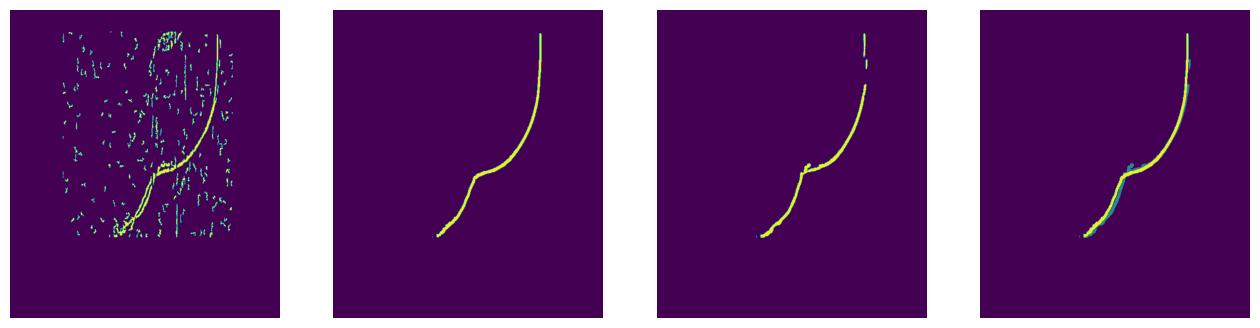

In [65]:
# model.train()
model.eval()
# target = train_dataset[np.random.randint(0,len(train_dataset)-1)]
target = test_dataset[np.random.randint(0,len(test_dataset)-1)]
# target = val_set[np.random.randint(0,len(val_set)-1)]
img = target["image"][None,:,:,:]
# img = torch.cat([img,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
img = img.to('cuda')
label1 = model(img)
label1 = label1.squeeze().to('cpu')
# transform = transforms.ToPILImage()
# img = transform(label1)
imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu().numpy()
imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu().numpy()

fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(16, 4))
ax = axs[0]
ax.imshow(img.cpu().detach().squeeze()[0], origin='lower', aspect = 'auto')
ax.axis('off')

ax = axs[1]
ax.imshow(imgO, origin='lower', aspect = 'auto')
ax.axis('off')

ax = axs[2]
ax.imshow(imgX, origin='lower', aspect = 'auto')
ax.axis('off')

imgX[imgO==1]=2
ax = axs[3]
ax.imshow(imgX, origin='lower', aspect = 'auto')
ax.axis('off')

# label0 = target["mask"][None,:,:,:]
# loss = dbcefloss(label1[None,0:2,:,:], label0[:,0,:,:]) + dbcefloss(label1[None,2:4,:,:], label0[:,1,:,:])
# print(loss.item())

In [6]:
model = UNet(n_channels=3, n_classes=4, bilinear=False)
model.load_state_dict(torch.load('checkpoints/dropout03/saved_model/'+'TOPHAT_checkpoint_epoch_10_10000.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

UNet(
  (inc): DoubleConv(
    (double_conv): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): ReLU(inplace=True)
      (2): GroupNorm(64, 64, eps=1e-05, affine=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): ReLU(inplace=True)
      (5): GroupNorm(64, 64, eps=1e-05, affine=True)
    )
  )
  (down1): Down(
    (maxpool_conv): Sequential(
      (0): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (1): DoubleConv(
        (double_conv): Sequential(
          (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (1): ReLU(inplace=True)
          (2): GroupNorm(128, 128, eps=1e-05, affine=True)
          (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (4): ReLU(inplace=True)
          (5): GroupNorm(128, 128, eps=1e-05, affine=True)
        )
      )
   

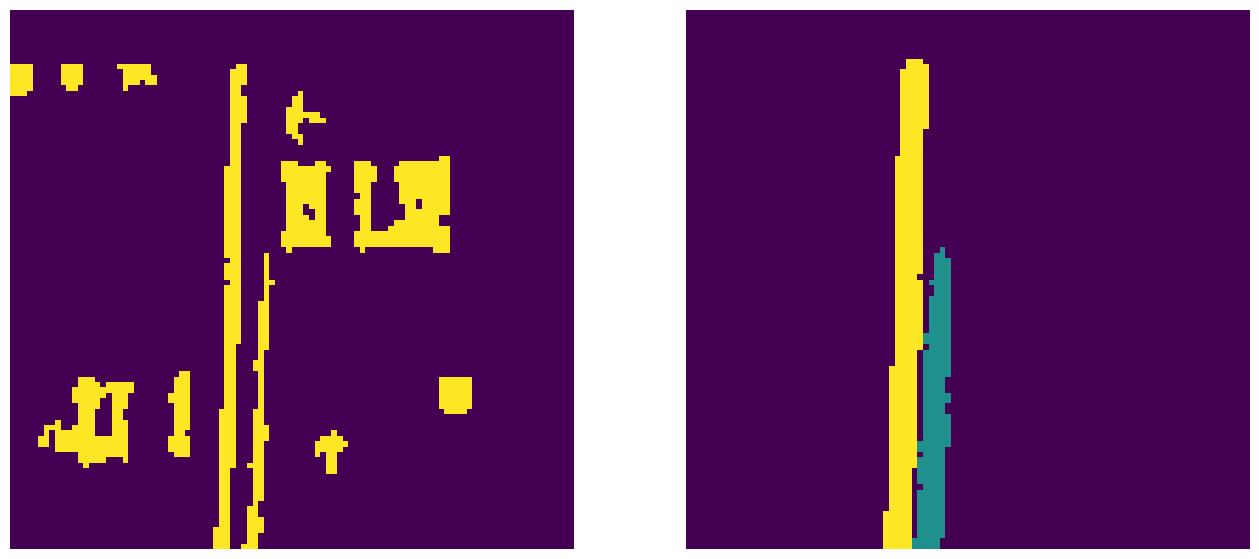

In [12]:
import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
testim = torch.from_numpy(testim['mask_full']).float()
XX, YY = torch.meshgrid(torch.linspace(0,1,testim.size()[0],dtype=torch.float32),torch.linspace(0,1,testim.size()[1],dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:] #resize_tr(testimage1[None,None,:,:])
    img = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu().numpy()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu().numpy()
    
    fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
    # plt.title(f'epoch{epoch_num}_{file}')
    ax = axs[0]
    ax.imshow(testimage1.detach().squeeze()[-100:,-100:], origin='lower', aspect = 'auto')
    ax.axis('off')
    ax = axs[1]

    imgX[imgO==1]=2
    ax.imshow(imgX[-100:,-100:], origin='lower', aspect = 'auto')
    ax.axis('off')
    # plt.savefig(f'testing_result/epoch{epoch_num}_{file[:-4]}.png', bbox_inches='tight')
    # plt.close()
